## 1. Import thư viện

In [1]:
import pandas as pd
import numpy as np
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
from pathlib import Path
import os
import json

print("Import thư viện thành công!")

/opt/anaconda3/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


Import thư viện thành công!


In [2]:
# Cấu hình đường dẫn theo cấu trúc project/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "weather_clean.csv"
OUTPUT_DIR = PROJECT_ROOT / "results" / "prophet"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_PARAMS_FILE = OUTPUT_DIR / "prophet_best_params.json"
OUTPUT_FILE = OUTPUT_DIR / "Prophet_Forecast_2026.csv"

## 2. Đọc và kiểm tra dữ liệu

In [3]:
# Đọc dữ liệu
df = pd.read_csv(DATA_PATH)

# Hiển thị 5 dòng đầu tiên
print("5 dòng dữ liệu đầu tiên:")
display(df.head())

# Kiểm tra thông tin dữ liệu
print("\nThông tin dữ liệu:")
df.info()

# Kiểm tra kích thước dữ liệu
print("\nKích thước dữ liệu:", df.shape)

5 dòng dữ liệu đầu tiên:


,date,tavg,tmin,tmax,prcp,snow,wspd,wpgt,pres,tsun,split,co_ngoai_lai_tavg
0,2020-01-01,0.4,-3.6,4.5,0.1,0,10.1,22.3,1035.5,438,train,False
1,2020-01-02,-0.5,-2.4,1.4,0.0,0,6.1,25.9,1031.2,0,train,False
2,2020-01-03,5.8,1.3,9.3,0.5,0,15.5,46.8,1024.4,0,train,False
3,2020-01-04,5.4,2.4,6.8,0.2,0,15.8,47.5,1031.5,0,train,False
4,2020-01-05,4.8,2.7,6.3,1.1,0,6.8,23.4,1036.6,0,train,False



Thông tin dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 2373 entries, 0 to 2372
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               2373 non-null   str    
 1   tavg               2373 non-null   float64
 2   tmin               2373 non-null   float64
 3   tmax               2373 non-null   float64
 4   prcp               2373 non-null   float64
 5   snow               2373 non-null   int64  
 6   wspd               2373 non-null   float64
 7   wpgt               2373 non-null   float64
 8   pres               2373 non-null   float64
 9   tsun               2373 non-null   int64  
 10  split              2373 non-null   str    
 11  co_ngoai_lai_tavg  2373 non-null   bool   
dtypes: bool(1), float64(7), int64(2), str(2)
memory usage: 206.4 KB

Kích thước dữ liệu: (2373, 12)


## 3. Tiền xử lý và kiểm tra dữ liệu

In [4]:

# Kiểm tra các cột cần thiết
required_columns = ["date", "tavg"]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Không tìm thấy cột {col} trong dữ liệu.")

# Chuyển cột date sang kiểu ngày tháng
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Chuyển tavg sang kiểu số
df["tavg"] = pd.to_numeric(df["tavg"], errors="coerce")

# Loại bỏ dòng thiếu ngày hoặc nhiệt độ
df = df.dropna(subset=["date", "tavg"]).copy()

# Sắp xếp dữ liệu theo ngày tăng dần
df = df.sort_values("date").reset_index(drop=True)

# Kiểm tra ngày bị trùng
duplicate_count = df["date"].duplicated().sum()

print("Số ngày bị trùng:", duplicate_count)

if duplicate_count > 0:
    raise ValueError("Dữ liệu có ngày bị trùng. Cần kiểm tra trước khi tiếp tục.")

# Kiểm tra khoảng thời gian
print("\nNgày bắt đầu:", df["date"].min().date())
print("Ngày kết thúc:", df["date"].max().date())

# Kiểm tra giá trị thiếu sau xử lý
print("\nSố giá trị thiếu:")
print(df[required_columns].isna().sum())

# Hiển thị dữ liệu sau xử lý
display(df.head())

Số ngày bị trùng: 0

Ngày bắt đầu: 2020-01-01
Ngày kết thúc: 2026-06-30

Số giá trị thiếu:
date    0
tavg    0
dtype: int64


,date,tavg,tmin,tmax,prcp,snow,wspd,wpgt,pres,tsun,split,co_ngoai_lai_tavg
0,2020-01-01,0.4,-3.6,4.5,0.1,0,10.1,22.3,1035.5,438,train,False
1,2020-01-02,-0.5,-2.4,1.4,0.0,0,6.1,25.9,1031.2,0,train,False
2,2020-01-03,5.8,1.3,9.3,0.5,0,15.5,46.8,1024.4,0,train,False
3,2020-01-04,5.4,2.4,6.8,0.2,0,15.8,47.5,1031.5,0,train,False
4,2020-01-05,4.8,2.7,6.3,1.1,0,6.8,23.4,1036.6,0,train,False


## 4. Chia dữ liệu Train, Validation và dữ liệu thực tế 2026

In [5]:
# 1. Xác định khoảng thời gian

TRAIN_START = pd.Timestamp("2020-01-01")
TRAIN_END = pd.Timestamp("2024-12-31")

VAL_START = pd.Timestamp("2025-01-01")
VAL_END = pd.Timestamp("2025-12-31")

TEST_START = pd.Timestamp("2026-01-01")
TEST_END = pd.Timestamp("2026-06-30")


# 2. Tạo tập Train: 2020-2024

train_data = df[
    (df["date"] >= TRAIN_START) &
    (df["date"] <= TRAIN_END)
].copy()


# 3. Tạo tập Validation: cả năm 2025

val_data = df[
    (df["date"] >= VAL_START) &
    (df["date"] <= VAL_END)
].copy()


# 4. Lấy dữ liệu thực tế năm 2026

actual_data = df[
    (df["date"] >= TEST_START) &
    (df["date"] <= TEST_END)
].copy()


# 5. Chuyển dữ liệu sang định dạng Prophet

train = train_data[["date", "tavg"]].rename(
    columns={"date": "ds", "tavg": "y"}
).copy()

val = val_data[["date", "tavg"]].rename(
    columns={"date": "ds", "tavg": "y"}
).copy()


# 6. Kiểm tra dữ liệu

print("TRAIN")
print("Số quan sát:", len(train))
print("Từ:", train["ds"].min().date())
print("Đến:", train["ds"].max().date())

print("\nVALIDATION")
print("Số quan sát:", len(val))
print("Từ:", val["ds"].min().date())
print("Đến:", val["ds"].max().date())

print("\nACTUAL 2026")
print("Số quan sát:", len(actual_data))
print("Từ:", actual_data["date"].min().date())
print("Đến:", actual_data["date"].max().date())


# 7. Kiểm tra dữ liệu

if train.empty or val.empty:
    raise ValueError("Train hoặc Validation không có dữ liệu.")

if train["ds"].max() >= val["ds"].min():
    raise ValueError("Train và Validation bị chồng lấn thời gian.")

if len(train) != train["ds"].nunique():
    raise ValueError("Train có ngày trùng.")

if len(val) != val["ds"].nunique():
    raise ValueError("Validation có ngày trùng.")


TRAIN
Số quan sát: 1827
Từ: 2020-01-01
Đến: 2024-12-31

VALIDATION
Số quan sát: 365
Từ: 2025-01-01
Đến: 2025-12-31

ACTUAL 2026
Số quan sát: 181
Từ: 2026-01-01
Đến: 2026-06-30


## 5. Chọn tham số cho mô hình Prophet

In [6]:
# Dữ liệu học khi thử tham số: 2020-2024
tune_train = train.copy()

# Dữ liệu kiểm định: cả năm 2025
tune_valid = val.copy()

print("Dữ liệu huấn luyện:",
      tune_train["ds"].min().date(),
      "đến",
      tune_train["ds"].max().date())

print("Dữ liệu kiểm định:",
      tune_valid["ds"].min().date(),
      "đến",
      tune_valid["ds"].max().date())

if tune_train.empty or tune_valid.empty:
    raise ValueError("Không đủ dữ liệu để chọn tham số.")


Dữ liệu huấn luyện: 2020-01-01 đến 2024-12-31
Dữ liệu kiểm định: 2025-01-01 đến 2025-12-31


In [7]:
# Các giá trị changepoint_prior_scale
cps_values = [0.01, 0.03, 0.05, 0.1, 0.2]

# Các giá trị seasonality_prior_scale
sps_values = [1.0, 5.0, 10.0]

# Các chế độ mùa vụ
modes = ["additive", "multiplicative"]

# Danh sách lưu kết quả
results = []

print("Số cấu hình sẽ thử:",
      len(cps_values) * len(sps_values) * len(modes))

Số cấu hình sẽ thử: 30


In [8]:
# Thử từng tổ hợp tham số
for cps in cps_values:
    for sps in sps_values:
        for mode in modes:

            # Khởi tạo mô hình
            temp_model = Prophet(
                yearly_seasonality=True,
                weekly_seasonality=True,
                daily_seasonality=False,
                changepoint_prior_scale=cps,
                seasonality_prior_scale=sps,
                seasonality_mode=mode,
                interval_width=0.95
            )

            # Huấn luyện trên Train 2020-2024
            temp_model.fit(tune_train)

            # Tạo ngày cần dự báo trong Validation
            tune_future = tune_valid[["ds"]].copy()

            # Dự báo
            tune_forecast = temp_model.predict(tune_future)

            # Ghép dự báo với thực tế
            tune_compare = tune_valid[["ds", "y"]].merge(
                tune_forecast[["ds", "yhat"]],
                on="ds",
                how="inner",
                validate="one_to_one"
            )

            # Tính MAE
            tune_mae = mean_absolute_error(
                tune_compare["y"],
                tune_compare["yhat"]
            )

            # Tính RMSE
            tune_rmse = np.sqrt(
                mean_squared_error(
                    tune_compare["y"],
                    tune_compare["yhat"]
                )
            )

            # Lưu kết quả
            results.append({
                "changepoint_prior_scale": cps,
                "seasonality_prior_scale": sps,
                "seasonality_mode": mode,
                "MAE": tune_mae,
                "RMSE": tune_rmse
            })

# Sắp xếp theo RMSE tăng dần, sau đó theo MAE
results_df = pd.DataFrame(results).sort_values(
    ["RMSE", "MAE"]
).reset_index(drop=True)

print("10 cấu hình tốt nhất:")
display(results_df.head(10))

print("Tổng số cấu hình đã thử:", len(results_df))

# Lấy cấu hình tốt nhất
best = results_df.iloc[0]

print("\n===== CẤU HÌNH TỐT NHẤT =====")
print(best)


12:00:02 - cmdstanpy - INFO - Chain [1] start processing
12:00:03 - cmdstanpy - INFO - Chain [1] done processing
12:00:03 - cmdstanpy - INFO - Chain [1] start processing
12:00:03 - cmdstanpy - INFO - Chain [1] done processing
12:00:03 - cmdstanpy - INFO - Chain [1] start processing
12:00:03 - cmdstanpy - INFO - Chain [1] done processing
12:00:03 - cmdstanpy - INFO - Chain [1] start processing
12:00:03 - cmdstanpy - INFO - Chain [1] done processing
12:00:03 - cmdstanpy - INFO - Chain [1] start processing
12:00:03 - cmdstanpy - INFO - Chain [1] done processing
12:00:03 - cmdstanpy - INFO - Chain [1] start processing
12:00:03 - cmdstanpy - INFO - Chain [1] done processing
12:00:03 - cmdstanpy - INFO - Chain [1] start processing
12:00:03 - cmdstanpy - INFO - Chain [1] done processing
12:00:04 - cmdstanpy - INFO - Chain [1] start processing
12:00:04 - cmdstanpy - INFO - Chain [1] done processing
12:00:04 - cmdstanpy - INFO - Chain [1] start processing
12:00:04 - cmdstanpy - INFO - Chain [1]

10 cấu hình tốt nhất:


,changepoint_prior_scale,seasonality_prior_scale,seasonality_mode,MAE,RMSE
0,0.05,5.0,additive,2.557701,3.215186
1,0.05,1.0,additive,2.558051,3.215421
2,0.10,5.0,additive,2.540808,3.216676
3,0.05,10.0,additive,2.560021,3.216778
4,0.10,10.0,additive,2.540717,3.216828
5,0.05,5.0,multiplicative,2.550222,3.218661
6,0.05,10.0,multiplicative,2.550157,3.218678
7,0.10,1.0,additive,2.540317,3.219938
8,0.05,1.0,multiplicative,2.553008,3.219957
9,0.10,5.0,multiplicative,2.540574,3.222519


Tổng số cấu hình đã thử: 30

===== CẤU HÌNH TỐT NHẤT =====
changepoint_prior_scale        0.05
seasonality_prior_scale         5.0
seasonality_mode           additive
MAE                        2.557701
RMSE                       3.215186
Name: 0, dtype: object


In [9]:
# Tạo dictionary chứa cấu hình tối ưu và kết quả trên tập Validation 2025
best_prophet_config = {
    "model": "Prophet",
    "train_period": f"{train['ds'].min().date()} to {train['ds'].max().date()}",
    "validation_period": f"{val['ds'].min().date()} to {val['ds'].max().date()}",
    "best_params": {
        "yearly_seasonality": True,
        "weekly_seasonality": True,
        "daily_seasonality": False,
        "changepoint_prior_scale": float(best["changepoint_prior_scale"]),
        "seasonality_prior_scale": float(best["seasonality_prior_scale"]),
        "seasonality_mode": str(best["seasonality_mode"]),
        "interval_width": 0.95
    },
    "validation_metrics": {
        "MAE": round(float(best["MAE"]), 6),
        "RMSE": round(float(best["RMSE"]), 6)
    }
}

# Xuất ra file JSON
with open(BEST_PARAMS_FILE, "w", encoding="utf-8") as f:
    json.dump(best_prophet_config, f, indent=4, ensure_ascii=False)

# Xuất thêm bảng toàn bộ 30 cấu hình thử nghiệm ra CSV
results_df.to_csv(OUTPUT_DIR / "prophet_tuning_results.csv", index=False, encoding="utf-8-sig")

print("Đã lưu cấu hình tốt nhất tại:", BEST_PARAMS_FILE)

Đã lưu cấu hình tốt nhất tại: /Users/tuong/Documents/MONHOCDAIHOC/năm IV-HK1 (2026-2027)/PP Nghiên Cứu KHDL/Frankfurt_Temperature_Forecasting/results/prophet/prophet_best_params.json


## 6. Dự báo và biểu đồ trên Validation 2025

In [10]:
# Khởi tạo mô hình tốt nhất
val_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    changepoint_prior_scale=float(
        best["changepoint_prior_scale"]
    ),
    seasonality_prior_scale=float(
        best["seasonality_prior_scale"]
    ),
    seasonality_mode=str(
        best["seasonality_mode"]
    ),
    interval_width=0.95
)
# Huấn luyện mô hình trên Train
# Huấn luyện trên dữ liệu 2020-2024
val_model.fit(train)

12:00:08 - cmdstanpy - INFO - Chain [1] start processing
12:00:08 - cmdstanpy - INFO - Chain [1] done processing


In [11]:
# Dự báo cả năm 2025
# Lấy danh sách ngày trong Validation
val_future = val[["ds"]].copy()

# Dự báo nhiệt độ
val_forecast = val_model.predict(val_future)

# Hiển thị kết quả dự báo
display(
    val_forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].head()
)

,ds,yhat,yhat_lower,yhat_upper
0,2025-01-01,5.535206,-0.975870,11.433968
1,2025-01-02,5.452471,-0.753424,11.687489
2,2025-01-03,5.302034,-0.593501,12.182921
3,2025-01-04,4.892590,-1.098509,10.872910
4,2025-01-05,4.776500,-1.912600,11.009371


In [12]:
# Ghép nhiệt độ thực tế và dự báo
val_compare = val[["ds", "y"]].merge(
    val_forecast[["ds", "yhat"]],
    on="ds",
    how="inner",
    validate="one_to_one"
)

# Đổi tên cột
val_compare = val_compare.rename(
    columns={
        "ds": "date",
        "y": "actual",
        "yhat": "predicted"
    }
)

# Sắp xếp theo ngày
val_compare = val_compare.sort_values(
    "date"
).reset_index(drop=True)

# Kiểm tra kết quả
display(val_compare.head())

print("Số ngày so sánh:", len(val_compare))


,date,actual,predicted
0,2025-01-01,3.4,5.535206
1,2025-01-02,3.2,5.452471
2,2025-01-03,1.4,5.302034
3,2025-01-04,0.1,4.892590
4,2025-01-05,1.5,4.776500


Số ngày so sánh: 365


In [13]:
# Tính MAE
val_mae = mean_absolute_error(
    val_compare["actual"],
    val_compare["predicted"]
)

# Tính RMSE
val_rmse = np.sqrt(
    mean_squared_error(
        val_compare["actual"],
        val_compare["predicted"]
    )
)

print("KẾT QUẢ VALIDATION 2025")
print("MAE:", round(val_mae, 4))
print("RMSE:", round(val_rmse, 4))

KẾT QUẢ VALIDATION 2025
MAE: 2.5577
RMSE: 3.2152


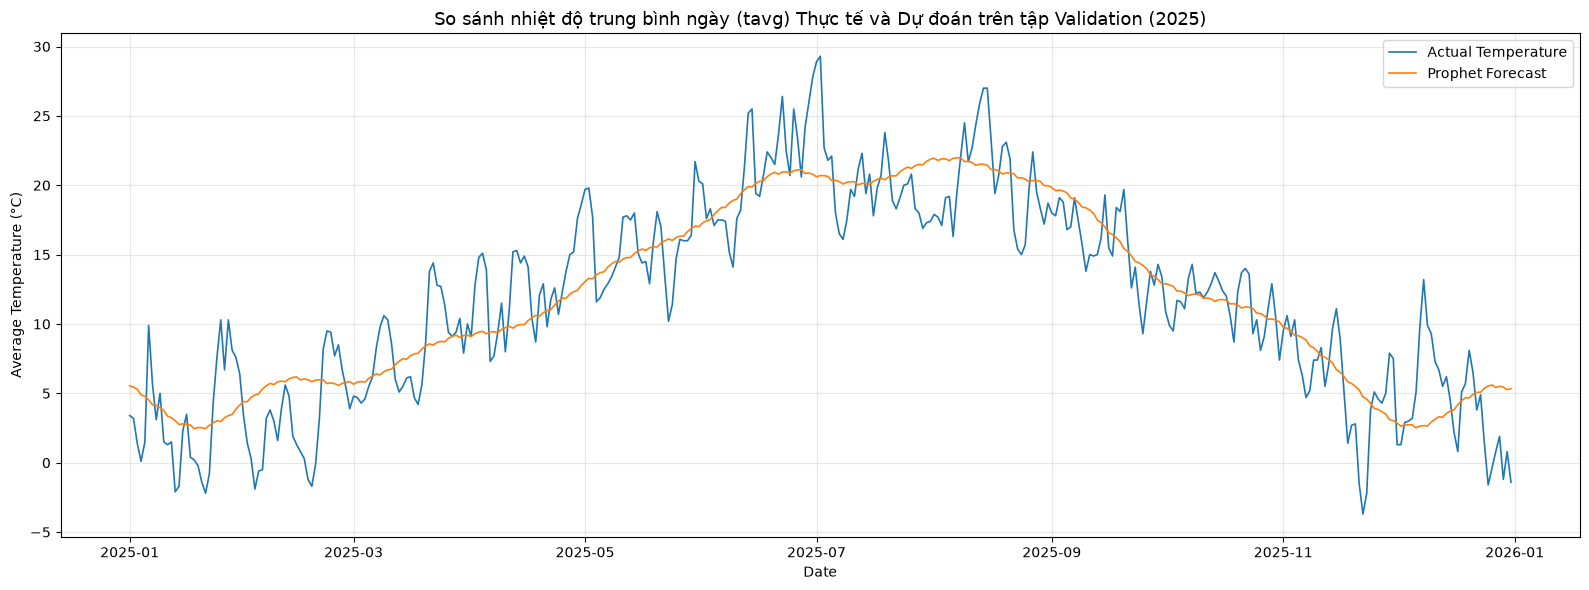

In [14]:
# Biểu đồ so sánh Actual và Predicted
plt.figure(figsize=(16, 6))
plt.plot(
    val_compare["date"],
    val_compare["actual"],
    label="Actual Temperature",
    linewidth=1.2
)
plt.plot(
    val_compare["date"],
    val_compare["predicted"],
    label="Prophet Forecast",
    linewidth=1.2
)
plt.title(
    "So sánh nhiệt độ trung bình ngày (tavg) "
    "Thực tế và Dự đoán trên tập Validation (2025)",
    fontsize=13
)
plt.xlabel("Date")
plt.ylabel("Average Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "prophet_validation_2025.png", dpi=300, bbox_inches="tight")
plt.show()


## 7. Huấn luyện mô hình cuối cùng trên dữ liệu 2020–2025

In [15]:
# Gộp Train 2020-2024 và Validation 2025
final_train = pd.concat(
    [train, val],
    ignore_index=True
)

# Sắp xếp theo ngày
final_train = final_train.sort_values(
    "ds"
).reset_index(drop=True)

print("===== FINAL TRAIN =====")
print("Số quan sát:", len(final_train))
print("Từ:", final_train["ds"].min().date())
print("Đến:", final_train["ds"].max().date())

===== FINAL TRAIN =====
Số quan sát: 2192
Từ: 2020-01-01
Đến: 2025-12-31


In [16]:
final_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    changepoint_prior_scale=float(
        best["changepoint_prior_scale"]
    ),
    seasonality_prior_scale=float(
        best["seasonality_prior_scale"]
    ),
    seasonality_mode=str(
        best["seasonality_mode"]
    ),
    interval_width=0.95
)

In [17]:
# Huấn luyện trên toàn bộ dữ liệu 2020-2025
final_model.fit(final_train)

print("Huấn luyện mô hình cuối cùng thành công!")

12:00:09 - cmdstanpy - INFO - Chain [1] start processing
12:00:09 - cmdstanpy - INFO - Chain [1] done processing


Huấn luyện mô hình cuối cùng thành công!


## 8. Dự báo nhiệt độ từ 01/01/2026 đến 30/06/2026

In [18]:
# Tạo danh sách ngày cần dự báo
future_2026 = pd.DataFrame({
    "ds": pd.date_range(
        start="2026-01-01",
        end="2026-06-30",
        freq="D"
    )
})

# Dự báo
forecast_2026 = final_model.predict(future_2026)

# Lấy các cột cần thiết
forecast_result = forecast_2026[
    ["ds", "yhat"]
].copy()

# Đổi tên cột
forecast_result = forecast_result.rename(
    columns={
        "ds": "date",
        "yhat": "prophet_forecast"
    }
)

# Kiểm tra kết quả
display(forecast_result.head())

print("Số ngày dự báo:", len(forecast_result))
print("Ngày đầu:", forecast_result["date"].min().date())
print("Ngày cuối:", forecast_result["date"].max().date())


,date,prophet_forecast
0,2026-01-01,4.413749
1,2026-01-02,4.280541
2,2026-01-03,4.051407
3,2026-01-04,3.866952
4,2026-01-05,3.642115


Số ngày dự báo: 181
Ngày đầu: 2026-01-01
Ngày cuối: 2026-06-30


## 9. So dự báo với nhiệt độ thực tế và xuất CSV

In [19]:
# Lấy nhiệt độ thực tế năm 2026
actual_2026 = actual_data[
    ["date", "tavg"]
].copy()

# Đổi tên cột nhiệt độ thực tế
actual_2026 = actual_2026.rename(
    columns={"tavg": "actual"}
)

# Ghép dự báo và thực tế theo ngày
result_csv = forecast_result.merge(
    actual_2026,
    on="date",
    how="left",
    validate="one_to_one"
)

# Sắp xếp đúng thứ tự 3 cột
result_csv = result_csv[
    ["date", "prophet_forecast", "actual"]
]

# Xuất file CSV
result_csv.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("Đã xuất file Prophet_Forecast_2026.csv")

# Kiểm tra kết quả
display(result_csv.head())

print("Số dòng:", len(result_csv))
print("Số giá trị thực tế bị thiếu:", result_csv["actual"].isna().sum())


Đã xuất file Prophet_Forecast_2026.csv


,date,prophet_forecast,actual
0,2026-01-01,4.413749,1.9
1,2026-01-02,4.280541,1.5
2,2026-01-03,4.051407,-0.3
3,2026-01-04,3.866952,-1.0
4,2026-01-05,3.642115,-4.3


Số dòng: 181
Số giá trị thực tế bị thiếu: 0
